# Car Price Prediction

In this project, we analyze a dataset of 26 vehicle features across the US automotive market to understand the primary factors driving car prices. We will begin with exploratory data analysis (EDA) to clean the dataset, identify key trends, and handle anomalies and outliers. Finally, we will build and evaluate a regression model to determine which specifications most strongly impact vehicle valuation, providing actionable pricing insights to guide strategic decisions.

In [ ]:
import pandas as pd

cars = pd.read_csv("CarPrice_Assignment.csv")
cars.head()

In [ ]:
cars.tail()

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
200,201,-1,volvo 145e (sw),gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845.0
201,202,-1,volvo 144ea,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045.0
202,203,-1,volvo 244dl,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485.0
203,204,-1,volvo 246,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.40,23.0,106,4800,26,27,22470.0
204,205,-1,volvo 264gl,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,19,25,22625.0


In [ ]:
cars.describe()

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


In [ ]:
cars.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocation    205 non-null    object 
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    object 
 15  cylindernumber    205 non-null    object 
 16  enginesize        205 non-null    int64  
 1

In [ ]:
cars.isnull().sum()

car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64

In [ ]:
cars.duplicated().sum()

np.int64(0)

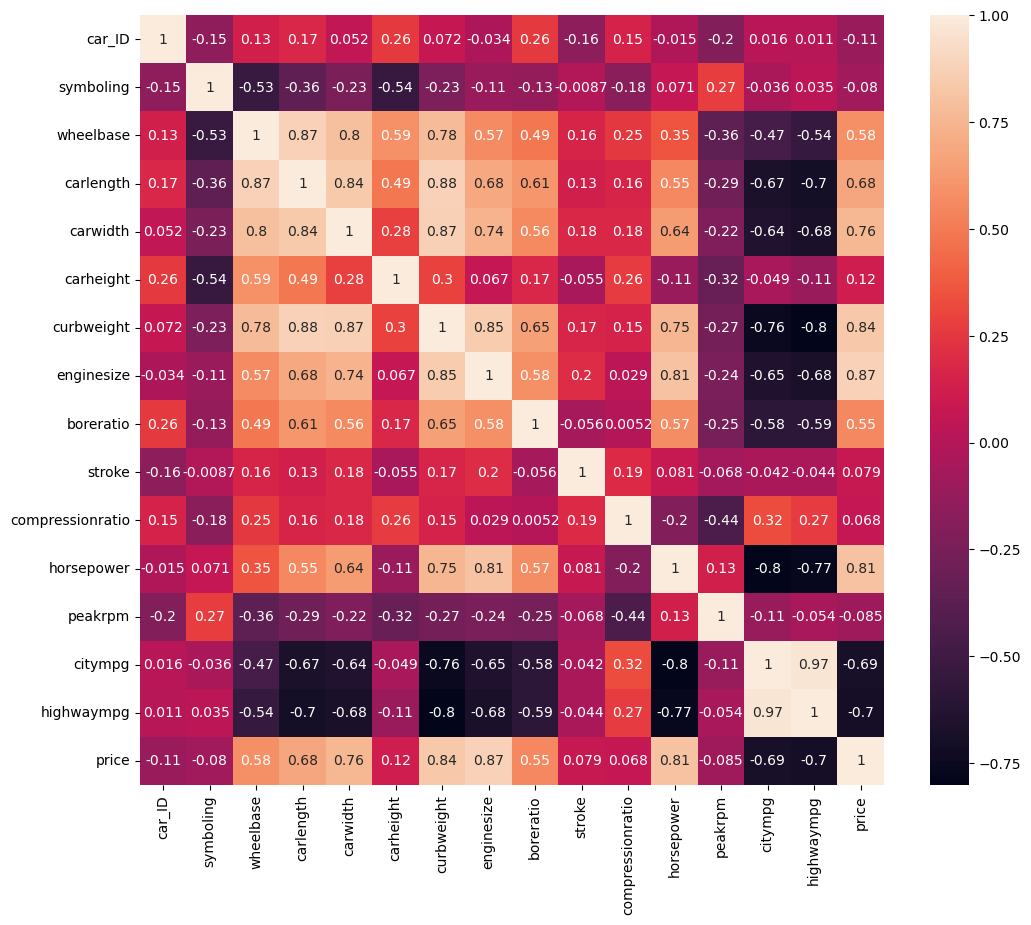

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

cars_numeric = cars.select_dtypes(include=[np.number])
corr_matrix = cars_numeric.corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True)
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

cat_cols = cars.select_dtypes(exclude="number").columns.tolist()
print(cat_cols)


['CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem']


In [ ]:

for col in cat_cols:
    print(col)
    print(cars[col].value_counts())
    print("---")

CarName
CarName
toyota corona           6
toyota corolla          6
peugeot 504             6
subaru dl               4
mitsubishi mirage g4    3
                       ..
mazda glc 4             1
mazda rx2 coupe         1
maxda glc deluxe        1
maxda rx3               1
volvo 246               1
Name: count, Length: 147, dtype: int64
---
fueltype
fueltype
gas       185
diesel     20
Name: count, dtype: int64
---
aspiration
aspiration
std      168
turbo     37
Name: count, dtype: int64
---
doornumber
doornumber
four    115
two      90
Name: count, dtype: int64
---
carbody
carbody
sedan          96
hatchback      70
wagon          25
hardtop         8
convertible     6
Name: count, dtype: int64
---
drivewheel
drivewheel
fwd    120
rwd     76
4wd      9
Name: count, dtype: int64
---
enginelocation
enginelocation
front    202
rear       3
Name: count, dtype: int64
---
enginetype
enginetype
ohc      148
ohcf      15
ohcv      13
dohc      12
l         12
rotor      4
dohcv      1
Name:

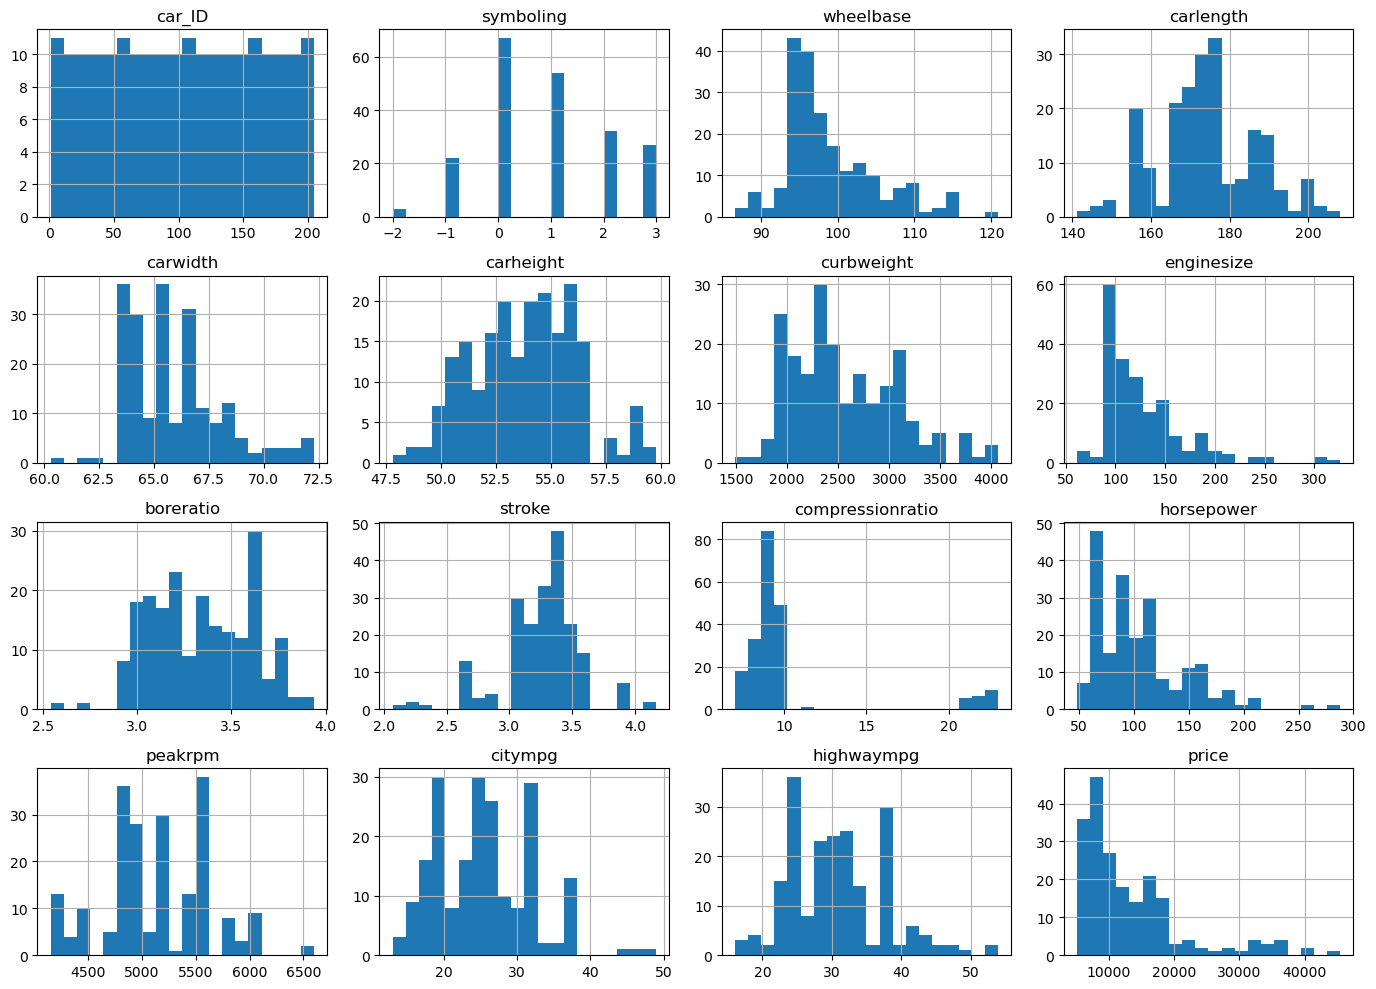

In [ ]:
num_cols = cars.select_dtypes(include="number").columns.tolist()
cars[num_cols].hist(figsize=(14, 10), bins=20)
plt.tight_layout()
plt.show()

In [ ]:
num_cols = cars.select_dtypes(include="number").columns.tolist()

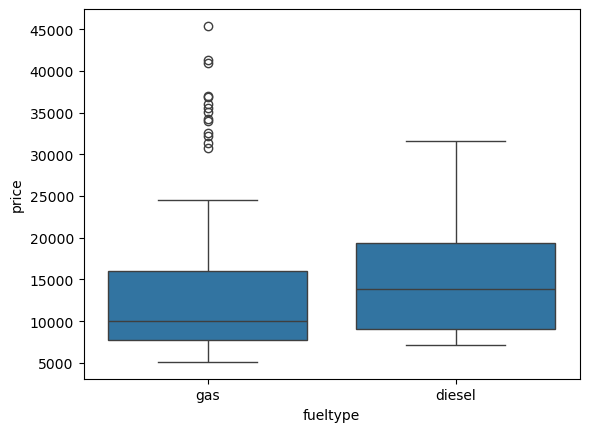

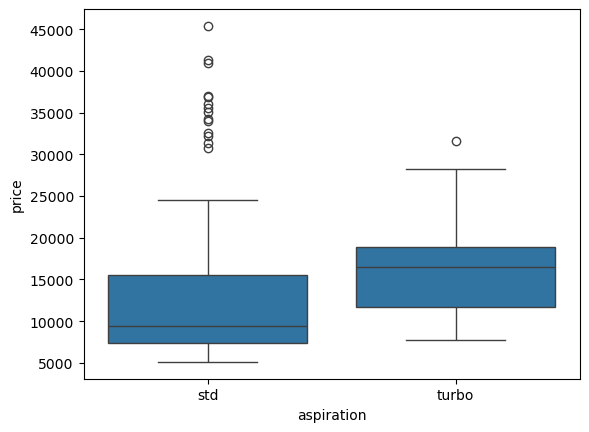

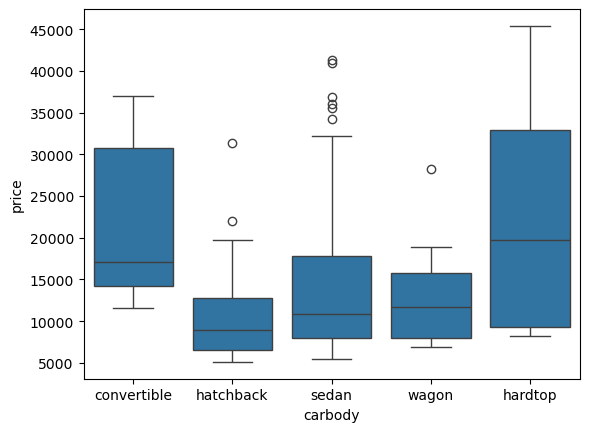

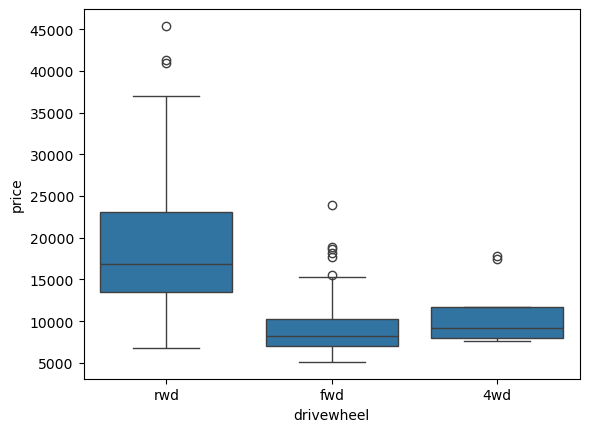

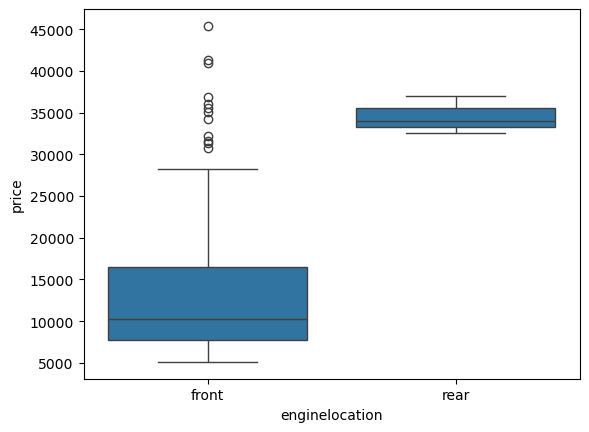

In [ ]:
for col in ["fueltype", "aspiration", "carbody", "drivewheel", "enginelocation"]:
    sns.boxplot(data=cars, x=col, y="price")
    plt.show()

In [ ]:
cars["car_volume"] = cars["carlength"] * cars["carwidth"] * cars["carheight"]

There are some brands that are miss spelled so we'll goint to change them 

In [ ]:
cars["brand"] = cars["CarName"].str.split().str[0].str.lower()
cars["brand"].value_counts()

brand
toyota         31
nissan         18
mazda          15
honda          13
mitsubishi     13
subaru         12
peugeot        11
volvo          11
dodge           9
volkswagen      9
bmw             8
buick           8
audi            7
plymouth        7
saab            6
isuzu           4
porsche         4
alfa-romero     3
jaguar          3
chevrolet       3
vw              2
maxda           2
renault         2
toyouta         1
vokswagen       1
mercury         1
porcshce        1
Name: count, dtype: int64

In [ ]:
fix = {
    "maxda": "mazda",
    "toyouta": "toyota",
    "porcshce": "porsche",
    "vw": "volkswagen",
    "vokswagen": "volkswagen",
}
cars["brand"] = cars["brand"].replace(fix)
for wrong, right in fix.items():
    cars["CarName"] = cars["CarName"].str.replace(rf"^{wrong}\b", right, regex=True)

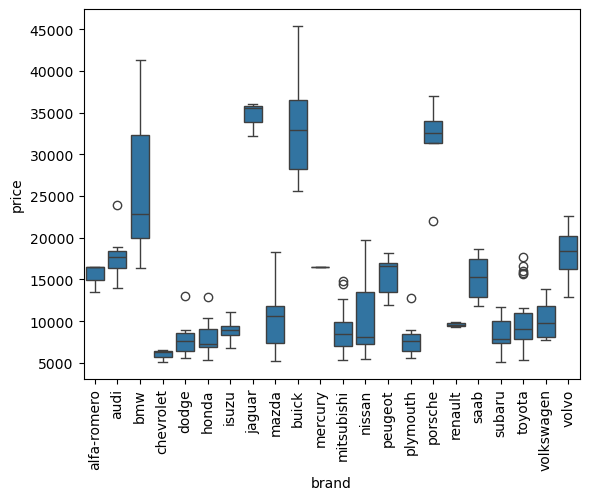

In [ ]:
sns.boxplot(data=cars, x="brand", y="price")
plt.xticks(rotation=90)
plt.show()

We'll remove too similar or repeating columns to prevent regression do unstable coefficiency

citympg and highwaympg gives similar graphs so we'll get rid of one of them also we extracted car volume from cars lenght, height and width so we'll wont need them too 

In [ ]:
cars = cars.drop(columns=["car_ID", "CarName", "carlength", "carwidth", "carheight", "curbweight", "horsepower", "highwaympg"])


In [ ]:
cars["doornumber"] = cars["doornumber"].map({"two": 2, "four": 4})
cars["cylindernumber"] = cars["cylindernumber"].map({
    "two": 2, "three": 3, "four": 4, "five": 5,
    "six": 6, "eight": 8, "twelve": 12,
})



In [ ]:
cars = pd.get_dummies(cars, drop_first=True)

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score, mean_squared_error

from sklearn.linear_model import (
    LinearRegression, Ridge, Lasso, ElasticNet,
    SGDRegressor, HuberRegressor, BayesianRidge,
)
from sklearn.tree import DecisionTreeRegressor, ExtraTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor, GradientBoostingRegressor,
    HistGradientBoostingRegressor, AdaBoostRegressor,
)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")

TREE_MODELS = {
    "Extra Tree", "Decision Tree", "Random Forest", "Gradient Boosting",
    "HistGradientBoosting", "AdaBoost", "XGBoost", "CatBoost",
}
SCALE_Y = {"SGD", "SVR", "MLP"}

def algo_test(x, y, plot=True):
    x = pd.DataFrame(x).astype(float)
    y = pd.Series(y).astype(float)

    algos = [
        LinearRegression(),
        Ridge(),
        Lasso(max_iter=10000),
        ElasticNet(max_iter=10000),
        SGDRegressor(max_iter=5000, tol=1e-3, random_state=42),
        HuberRegressor(max_iter=500),
        BayesianRidge(),
        ExtraTreeRegressor(random_state=42),
        DecisionTreeRegressor(random_state=42),
        RandomForestRegressor(random_state=42, n_jobs=-1),
        GradientBoostingRegressor(random_state=42),
        HistGradientBoostingRegressor(random_state=42),
        AdaBoostRegressor(random_state=42),
        XGBRegressor(verbosity=0, n_jobs=-1, random_state=42),
        CatBoostRegressor(verbose=0, random_state=42),
        KNeighborsRegressor(),
        SVR(),
        MLPRegressor(max_iter=500, hidden_layer_sizes=(64, 32), random_state=42),
    ]
    algo_names = [
        "Linear", "Ridge", "Lasso", "ElasticNet", "SGD", "Huber", "BayesianRidge",
        "Extra Tree", "Decision Tree", "Random Forest", "Gradient Boosting",
        "HistGradientBoosting", "AdaBoost", "XGBoost", "CatBoost",
        "KNN", "SVR", "MLP",
    ]

    x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size=0.20, random_state=42
    )

    results = []
    for name, algo in zip(algo_names, algos):
        if name in TREE_MODELS:
            x_tr, x_te = x_train, x_test
        else:
            x_scaler = MinMaxScaler()
            x_tr = x_scaler.fit_transform(x_train)
            x_te = x_scaler.transform(x_test)

        y_tr = y_train
        y_scaler = None
        if name in SCALE_Y:
            y_scaler = MinMaxScaler()
            y_tr = y_scaler.fit_transform(y_train.to_numpy().reshape(-1, 1)).ravel()

        preds = algo.fit(x_tr, y_tr).predict(x_te)
        if y_scaler is not None:
            preds = y_scaler.inverse_transform(np.asarray(preds).reshape(-1, 1)).ravel()

        results.append({
            "Model": name,
            "R2": r2_score(y_test, preds),
            "RMSE": mean_squared_error(y_test, preds) ** 0.5,
        })

    result_df = pd.DataFrame(results).sort_values("R2", ascending=False).reset_index(drop=True)
    print(result_df)

    if plot:
        plt.figure(figsize=(18, 7))
        plt.subplot(1, 2, 1)
        sns.barplot(data=result_df, x="Model", y="R2")
        plt.xticks(rotation=45, ha="right")
        plt.title("R2")
        plt.subplot(1, 2, 2)
        sns.barplot(data=result_df, x="Model", y="RMSE")
        plt.xticks(rotation=45, ha="right")
        plt.title("RMSE")
        plt.tight_layout()
        plt.show()

    return result_df

                   Model        R2         RMSE
0          Random Forest  0.954291  1899.599703
1               CatBoost  0.946315  2058.669819
2      Gradient Boosting  0.938527  2202.928558
3                XGBoost  0.931128  2331.743024
4          Decision Tree  0.923815  2452.419426
5             Extra Tree  0.920975  2497.714990
6               AdaBoost  0.914200  2602.577706
7                 Linear  0.895538  2871.700705
8                  Lasso  0.891233  2930.269550
9                    MLP  0.878403  3098.279385
10         BayesianRidge  0.872802  3168.841955
11  HistGradientBoosting  0.857251  3356.963611
12                 Ridge  0.857104  3358.690582
13                 Huber  0.850237  3438.439000
14                   SVR  0.822902  3739.089390
15                   KNN  0.789977  4071.860727
16                   SGD  0.629019  5411.719174
17            ElasticNet  0.504076  6257.016819


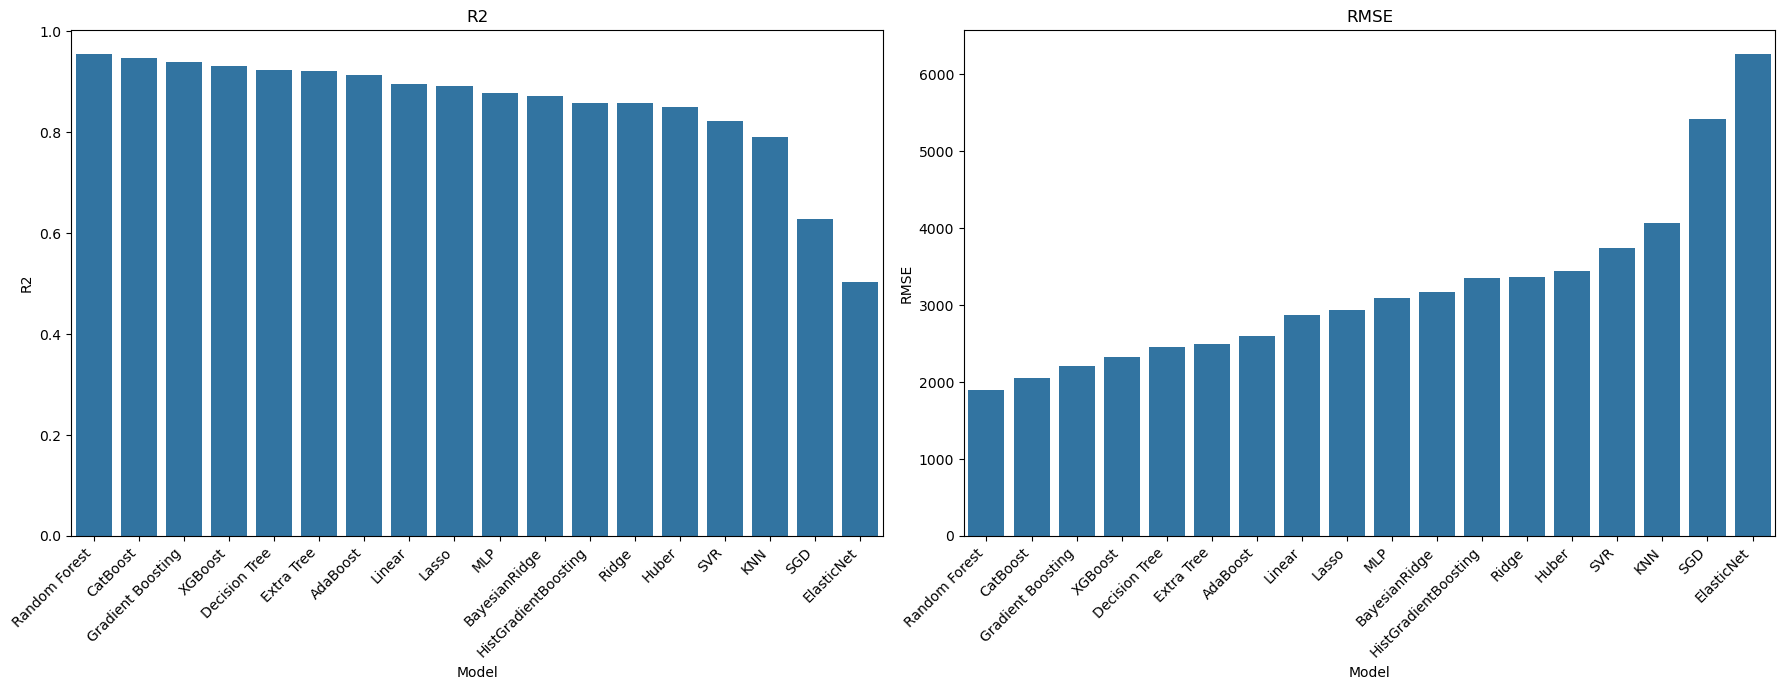

,Model,R2,RMSE
0,Random Forest,0.954291,1899.599703
1,CatBoost,0.946315,2058.669819
2,Gradient Boosting,0.938527,2202.928558
3,XGBoost,0.931128,2331.743024
4,Decision Tree,0.923815,2452.419426
5,Extra Tree,0.920975,2497.714990
6,AdaBoost,0.914200,2602.577706
7,Linear,0.895538,2871.700705
8,Lasso,0.891233,2930.269550
9,MLP,0.878403,3098.279385


In [ ]:
x = cars.drop(columns = "price")
y = cars["price"]

algo_test(x, y)

In [ ]:
import joblib
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import r2_score, mean_squared_error

X = cars.drop(columns="price").astype(float)
y = cars["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

search = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    {
        "n_estimators": [200, 400],
        "max_depth": [None, 8, 12],
        "min_samples_leaf": [1, 2, 4],
    },
    cv=5,
    scoring="r2",
    n_jobs=-1,
)
search.fit(X_train, y_train)
model = search.best_estimator_

pred = model.predict(X_test)
print(search.best_params_)
print(r2_score(y_test, pred))
print(mean_squared_error(y_test, pred) ** 0.5)

joblib.dump({"model": model, "columns": list(X.columns)}, "car_price_model.joblib",)

{'max_depth': 8, 'min_samples_leaf': 2, 'n_estimators': 200}
0.950536315668334
1976.0723996513498


['car_price_model.joblib']

<Axes: xlabel='price', ylabel='Density'>

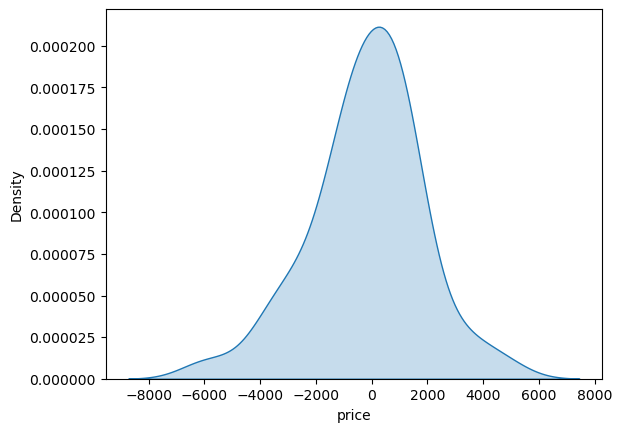

In [ ]:
residuals = y_test - pred
sns.kdeplot(residuals, fill=True)

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

tf.keras.utils.set_random_seed(42)

x_train, x_test, y_train, y_test = train_test_split(
    x.astype(float), y.astype(float), test_size=0.20, random_state=42
)

x_scaler = MinMaxScaler()
y_scaler = MinMaxScaler()
x_tr = x_scaler.fit_transform(x_train)
x_te = x_scaler.transform(x_test)
y_tr = y_scaler.fit_transform(y_train.to_numpy().reshape(-1, 1))

dl = keras.Sequential([
    keras.layers.Input(shape=(x_tr.shape[1],)),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(1),
])
dl.compile(optimizer="adam", loss="mse")
dl.fit(x_tr, y_tr, validation_split=0.2, epochs=120, batch_size=16, callbacks=[keras.callbacks.EarlyStopping(patience=12, tore_best_weights=True)],
    verbose=0)

pred = y_scaler.inverse_transform(dl.predict(x_te, verbose=0)).ravel()
print("DeepLearning R2  :", r2_score(y_test, pred))
print("DeepLearning RMSE:", mean_squared_error(y_test, pred) ** 0.5)

# Conclusion

In the end, i fixed the misspelled brand names, and dropped columns that were too similar so the regression would stay stable. We also turned the text columns into numbers and compared a bunch of models. Random Forest gave the best test result, with an R² around 0.95 and an RMSE around 1900. After a small tune (n_estimators=200, max_depth=8, min_samples_leaf=2) the test R² stayed at 0.95, and we saved that model as car_price_model.joblib.